## **Logistic Regression: Breast Cancer Classification**

**Project overview**

This project uses Logistic Regression to classify breast cancer tumors as malignant or benign using measurements computed from digitized images of fine needle aspirates (FNA) of breast masses.

The goal is to build a clear, reproducible machine-learning workflow: load the dataset, explore it, split the data, scale features without data leakage, train a model, and evaluate its performance with multiple classification metrics.

### **Learning objectives**

- Understand a binary classification problem.
- Split data into training and testing sets.
- Use StandardScaler correctly through a Pipeline.
- Train a Logistic Regression model.
- Evaluate predictions using accuracy, precision, recall, F1-score, a confusion matrix, and ROC-AUC.
- Inspect model errors and feature coefficients.

## **Dataset**

Using built-in dataset 'Breast Cancer Wisconsin (Diagnostic)' provided by scikit-learn. It contains 569 samples and 30 numeric features.

Target labels:
- 0 = malignant
- 1 = benign

Because this is a medical dataset, this notebook is an educational demonstration only—not a clinical diagnostic tool.

## **1. Import Libraries**

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

## **2. Load the dataset**

Load the dataset and check its size, feature names, and target distribution.

In [29]:
cancer = load_breast_cancer(as_frame=True)

X = cancer.data
y = cancer.target

print("Dataset shape:", X.shape)
print("Target names:", cancer.target_names)
print("\nTarget counts:")
print(y.map({0: "malignant", 1: "benign"}).value_counts())

Dataset shape: (569, 30)
Target names: ['malignant' 'benign']

Target counts:
target
benign       357
malignant    212
Name: count, dtype: int64


In [30]:
# Preview the first five rows
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## **3. Basic data checks**

Check missing values and summary statistics before training.

In [32]:
print("Missing values in features:", X.isnull().sum().sum())
X.describe()

Missing values in features: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## **4. Split the data**

Keep 20% of the observations for final testing. stratify=y keeps the target-class proportions similar in both sets. random_state=42 makes the split reproducible.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (455, 30)
Testing features: (114, 30)


## **5. Build and train the model**

Feature scaling is important for Logistic Regression because the features use different numeric scales. A Pipeline fits the scaler only on the training data and then applies the same transformation to test data, helping prevent data leakage.

In [20]:
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=5000, random_state=42))
])

model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic_regression',
                 LogisticRegression(max_iter=5000, random_state=42))])

## **6. Make predictions**

The model predicts a class label and also estimates the probability of each class.

In [21]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Probability_Benign": y_probability
})
predictions["Actual_Label"] = predictions["Actual"].map({0: "malignant", 1: "benign"})
predictions["Predicted_Label"] = predictions["Predicted"].map({0: "malignant", 1: "benign"})

predictions.head(10)

,Actual,Predicted,Probability_Benign,Actual_Label,Predicted_Label
0,0,0,5.888242e-08,malignant,malignant
1,1,1,9.999887e-01,benign,benign
2,0,0,6.410825e-03,malignant,malignant
3,1,1,5.335085e-01,benign,benign
4,0,0,6.525001e-10,malignant,malignant
5,1,1,9.921604e-01,benign,benign
6,1,1,9.999828e-01,benign,benign
7,0,0,5.635275e-07,malignant,malignant
8,0,0,5.431637e-05,malignant,malignant
9,0,0,8.041849e-11,malignant,malignant


## **7. Evaluate the model**

Accuracy is the fraction of all predictions that are correct. Precision, recall, and F1-score provide additional information about class-specific performance. ROC-AUC measures how well the model ranks positive cases across classification thresholds.

In [22]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (benign class)": precision_score(y_test, y_pred, pos_label=1),
    "Recall (benign class)": recall_score(y_test, y_pred, pos_label=1),
    "F1-score (benign class)": f1_score(y_test, y_pred, pos_label=1),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}

metrics_df = pd.DataFrame(
    {"Metric": metrics.keys(), "Score": metrics.values()}
)
metrics_df

,Metric,Score
0,Accuracy,0.982456
1,Precision (benign class),0.986111
2,Recall (benign class),0.986111
3,F1-score (benign class),0.986111
4,ROC-AUC,0.995370


In [23]:
print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names,
    digits=4
))

              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



## **8. Confusion matrix**

The confusion matrix compares the actual labels with the predicted labels. Rows represent actual classes and columns represent predicted classes.

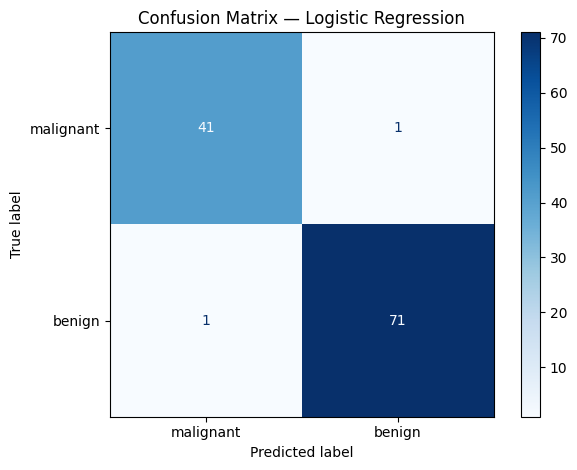

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=cancer.target_names,
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

## **9. ROC curve**

The ROC curve shows the trade-off between the true-positive rate and false-positive rate at different thresholds. The AUC summarizes this curve.

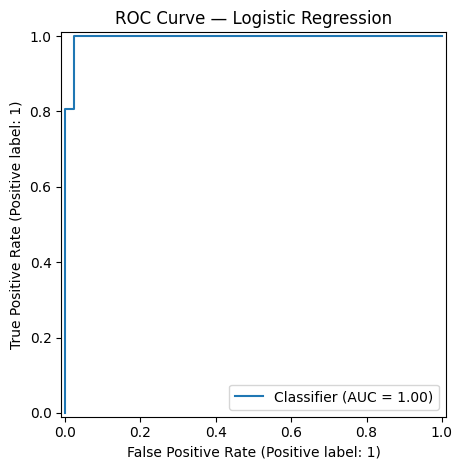

In [25]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve — Logistic Regression")
plt.tight_layout()
plt.show()

## **10. Review incorrect predictions**

Inspect the observations where the predicted class differs from the actual class. In a medical classification setting, errors need careful analysis; false negatives and false positives can have different consequences.

In [26]:
errors = predictions[predictions["Actual"] != predictions["Predicted"]]
print("Number of incorrect predictions:", len(errors))
errors

Number of incorrect predictions: 2


,Actual,Predicted,Probability_Benign,Actual_Label,Predicted_Label
16,1,0,0.365862,benign,malignant
53,0,1,0.908728,malignant,benign


## **11. Inspect feature coefficients**

The coefficient sign indicates the direction of the feature's relationship with the model's log-odds of class 1 (benign), while holding other features constant. Since the features were standardized, the coefficients are more comparable than coefficients from unscaled inputs. Coefficients should not be interpreted as proof of causation.

In [33]:
coefficients = pd.Series(
    model.named_steps["logistic_regression"].coef_[0],
    index=X.columns
).sort_values()

print("Features associated with lower predicted log-odds of benign (negative coefficients):")
display(coefficients.head(10).to_frame("Coefficient"))

print("\nFeatures associated with higher predicted log-odds of benign (positive coefficients):")
display(coefficients.tail(10).sort_values(ascending=False).to_frame("Coefficient"))

Features associated with lower predicted log-odds of benign (negative coefficients):


,Coefficient
worst texture,-1.255088
radius error,-1.082965
worst concave points,-0.953686
worst area,-0.947756
worst radius,-0.947616
worst symmetry,-0.939181
area error,-0.929104
worst concavity,-0.823151
worst perimeter,-0.763220
worst smoothness,-0.746625



Features associated with higher predicted log-odds of benign (positive coefficients):


,Coefficient
mean compactness,0.648342
compactness error,0.647227
fractal dimension error,0.437894
symmetry error,0.360492
texture error,0.248823
mean fractal dimension,0.199732
concavity error,0.160563
worst compactness,0.055514
smoothness error,-0.160276
mean symmetry,-0.167233


## **12. Conclusion**

This notebook demonstrates an end-to-end binary classification workflow with Logistic Regression. Use the evaluation metrics and plots together rather than relying on accuracy alone.

### **Possible improvements**

- Compare Logistic Regression with other classifiers using cross-validation.
- Tune model hyperparameters on training data only.
- Examine precision and recall for each class and select thresholds based on the task's needs.
- Validate on independent, representative data before considering any real-world use.

### **Key takeaways**

- Split data before fitting preprocessing steps.
- Use a pipeline to prevent preprocessing leakage.
- Evaluate classification with multiple metrics.
- Medical machine-learning examples are educational and must not replace professional diagnosis.